# Clasificación de residuos para reciclaje con IA
### Machine Learning · Universidad del Desarrollo · Certamen I

**Grupo 1:** Tomás Allende · Felipe Castillo · Juan Costa

La idea: entrenar un modelo que mire la foto de un residuo y diga a qué categoría pertenece (cartón, vidrio, metal, papel, plástico o resto). Después, en la app web, ese resultado se le entrega a un modelo de lenguaje (LLM) que da una recomendación de reciclaje.

Imagen -> modelo preentrenado (clase + confianza) -> resultado visual -> LLM -> recomendación

| Enfoque | Librería | Modelo | Idea |
|---|---|---|---|
| **Línea base** | `transformers` | CLIP | Usar un modelo **tal cual**, sin entrenar |
| **Modelo elegido** | `timm` | EfficientNet-B0 | **Transfer learning**: adaptar una red ya entrenada a nuestras 6 clases |

Comparamos los dos para justificar por qué elegimos el segundo.

> Prototipo educativo. En Colab, antes de empezar: *Entorno de ejecución -> Cambiar tipo de entorno -> GPU*.

## 0. Librerías

In [1]:
# Instala lo que no viene por defecto (en Colab la mayoría ya está):
!pip install -q timm transformers huggingface_hub scikit-learn seaborn

import os, random, zipfile, numpy as np, matplotlib.pyplot as plt, torch   # utilidades, cálculo, gráficos y deep learning
from PIL import Image                                                       # abrir y revisar imágenes
from huggingface_hub import hf_hub_download                                 # bajar el archivo del dataset
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,       # métricas de evaluación
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

DISP = "cuda" if torch.cuda.is_available() else "cpu"                       # usa GPU si está disponible
print("Dispositivo:", DISP)

Dispositivo: cuda


## 1. Los datos

Usamos **TrashNet**: fotos de residuos tomadas sobre fondo blanco para un proyecto de Stanford.

| Aspecto | Detalle |
|---|---|
| Origen | TrashNet · Gary Thung y Mindy Yang (Stanford, 2016) · en Hugging Face: `garythung/trashnet` |
| Licencia | MIT |
| Clases | cartón · vidrio · metal · papel · plástico · resto (no reciclable) |
| Total | 2.527 fotos |
| Por clase | papel 594 · vidrio 501 · plástico 482 · metal 410 · cartón 403 · **resto 137** |
| División | 70 % entrenamiento · 15 % validación · 15 % prueba (**estratificada**: misma proporción de cada clase en las tres partes) |

**Limitaciones:** son fotos de estudio (fondo blanco y buena luz), así que el modelo puede fallar con fotos reales (basura mezclada, mala luz). Las clases están **desbalanceadas** (la clase *resto* tiene muchas menos fotos que *papel*). Además es un solo origen, no representa todos los envases del mundo.

**Referencias**
- Thung, G. & Yang, M. (2016). *TrashNet*. Stanford. https://github.com/garythung/trashnet
- Dataset en Hugging Face: https://huggingface.co/datasets/garythung/trashnet

### 1.1 Descargar y revisar la calidad de las imágenes
Bajamos el dataset (un `.zip` con una carpeta por clase) y, antes de usarlo, **revisamos que todas las imágenes se abran bien**: las convertimos a color (RGB) y descartamos cualquiera que esté corrupta o vacía. También miramos cuántas fotos tiene cada clase para ver el desbalance.

In [2]:
zip_path = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset")  # baja el archivo
with zipfile.ZipFile(zip_path) as z:
    z.extractall("origen")                       # lo descomprime en la carpeta "origen"
RAIZ = "origen/dataset-resized"                  # dentro están las carpetas cardboard, glass, metal, ...

ES = {"cardboard":"carton", "glass":"vidrio", "metal":"metal",   # traducimos el nombre de cada clase al español
      "paper":"papel", "plastic":"plastico", "trash":"resto"}

validas = {c: [] for c in ES.values()}           # aquí guardamos las rutas de las fotos que están OK
corruptas = 0
for clase_en, clase_es in ES.items():
    carpeta = f"{RAIZ}/{clase_en}"
    for archivo in os.listdir(carpeta):
        if not archivo.lower().endswith((".jpg", ".jpeg", ".png")):
            continue                             # saltamos archivos que no sean imágenes
        ruta = f"{carpeta}/{archivo}"
        try:
            Image.open(ruta).convert("RGB")      # intentamos abrirla y pasarla a color
            validas[clase_es].append(ruta)       # si funcionó, es válida
        except Exception:
            corruptas += 1                        # si falló, la descartamos

print(f"Imágenes corruptas o ilegibles descartadas: {corruptas}\n")
for c in sorted(validas, key=lambda k: -len(validas[k])):
    print(f"  {c:9s} {len(validas[c])} fotos")
menor = min(validas, key=lambda k: len(validas[k]))
print(f"\nTotal válidas: {sum(len(v) for v in validas.values())}")
print(f"Clase con menos fotos: {menor} ({len(validas[menor])}) -> confirma el desbalance")

Imágenes corruptas o ilegibles descartadas: 0

  papel     594 fotos
  vidrio    501 fotos
  plastico  482 fotos
  metal     410 fotos
  carton    403 fotos
  resto     137 fotos

Total válidas: 2527
Clase con menos fotos: resto (137) -> confirma el desbalance


**Pregunta 1.** ¿Cuántas clases tiene el problema? ¿Es binario o multiclase? Si un modelo adivinara al azar, ¿qué accuracy tendría?

> _Respuesta:_ 6 clases **multiclase**. Adivinando al azar acertaría 1/6 ≈ **16,7 %**. Ese es el piso contra el que comparamos.

### 1.2 Dividir en train / val / test y guardar en carpetas
Repartimos las fotos buenas en tres grupos (70 % / 15 % / 15 %) **dentro de cada clase**, para que las tres partes tengan la misma mezcla. Usamos una **semilla fija** (42) para que la división sea siempre igual. Guardamos cada grupo en `datos/train|val|test/<clase>/`, que es el formato que entiende `timm`.

In [3]:
DATOS = "datos"
rng = random.Random(42)                          # semilla fija -> división reproducible
reparto = {"train": [], "val": [], "test": []}

for clase_es, rutas in validas.items():
    rutas = rutas[:]; rng.shuffle(rutas)         # mezclamos las fotos de la clase
    n = len(rutas); corte1 = int(n * 0.70); corte2 = int(n * 0.85)
    reparto["train"] += [(r, clase_es) for r in rutas[:corte1]]
    reparto["val"]   += [(r, clase_es) for r in rutas[corte1:corte2]]
    reparto["test"]  += [(r, clase_es) for r in rutas[corte2:]]

for parte, pares in reparto.items():             # copiamos cada foto a su carpeta
    for k, (r, clase_es) in enumerate(pares):
        dest = f"{DATOS}/{parte}/{clase_es}"; os.makedirs(dest, exist_ok=True)
        Image.open(r).convert("RGB").save(f"{dest}/{k:05d}.jpg")

CLASES = sorted(os.listdir(f"{DATOS}/train"))    # orden alfabético = el que usará el modelo
print("Clases (orden del modelo):", CLASES, "\n")
for c in CLASES:
    print(f"{c:9s} train={len(os.listdir(f'{DATOS}/train/{c}')):4d}  "
          f"val={len(os.listdir(f'{DATOS}/val/{c}')):3d}  "
          f"test={len(os.listdir(f'{DATOS}/test/{c}')):3d}")

Clases (orden del modelo): ['carton', 'metal', 'papel', 'plastico', 'resto', 'vidrio'] 

carton    train= 282  val= 60  test= 61
metal     train= 287  val= 61  test= 62
papel     train= 415  val= 89  test= 90
plastico  train= 337  val= 72  test= 73
resto     train=  95  val= 21  test= 21
vidrio    train= 350  val= 75  test= 76


### 1.3 Mirar algunos ejemplos

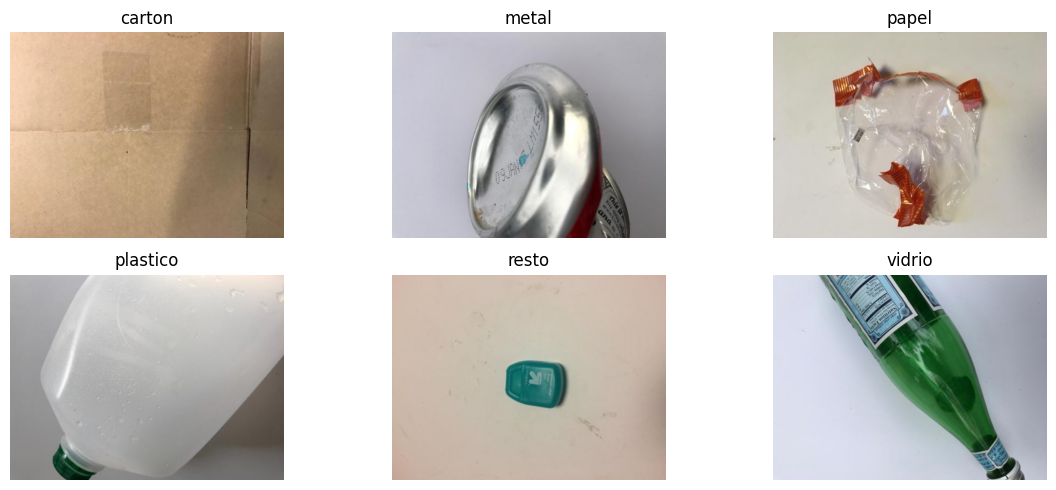

In [4]:
plt.figure(figsize=(12, 5))
for j, c in enumerate(CLASES):                           # una foto de ejemplo por clase
    archivos = os.listdir(f"{DATOS}/train/{c}")
    plt.subplot(2, 3, j + 1)
    plt.imshow(Image.open(f"{DATOS}/train/{c}/{archivos[0]}"))
    plt.title(c); plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Evaluación común
Para comparar los dos enfoques de forma justa, ambos se prueban con las **mismas fotos** del conjunto de prueba y la **misma métrica** (accuracy = % de aciertos). Cada enfoque solo tiene que aportar una función `predecir(ruta) clase`.

In [5]:
test = [(f"{DATOS}/test/{c}/{a}", c) for c in CLASES for a in os.listdir(f"{DATOS}/test/{c}")]
print("Imágenes de prueba:", len(test))
RESULTADOS = {}                                          # aquí guardamos la accuracy de cada enfoque

def evaluar(nombre, predecir):
    reales = [c for _, c in test]                        # clase verdadera de cada foto
    preds  = [predecir(r) for r, _ in test]              # clase que predice el enfoque
    RESULTADOS[nombre] = accuracy_score(reales, preds)
    print(f"{nombre}: accuracy = {RESULTADOS[nombre]:.1%}")
    return reales, preds

Imágenes de prueba: 383


## 3. Línea base · CLIP sin entrenar (*zero-shot*)
**CLIP** aprendió de millones de pares de imagen + texto sacados de internet. Le damos una frase en inglés por clase y él elige la foto que más se parece a cada frase, **sin que entrenemos nada**. Es nuestra vara de comparación: ¿cuánto mejora entrenar un modelo propio frente a usar uno general tal cual?

In [6]:
from transformers import pipeline
GPU = 0 if DISP == "cuda" else -1
clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=GPU)

TEXTOS = {                                                        # una descripción en inglés por clase
    "carton":   "a photo of cardboard",
    "vidrio":   "a photo of a glass bottle or glass jar",
    "metal":    "a photo of a metal can or aluminum",
    "papel":    "a photo of paper",
    "plastico": "a photo of a plastic bottle or plastic packaging",
    "resto":    "a photo of general trash that cannot be recycled",
}
A_CLASE = {v: k for k, v in TEXTOS.items()}                       # de la frase en inglés de vuelta a la clase

def predecir_clip(ruta):
    r = clip(ruta, candidate_labels=list(TEXTOS.values()))
    return A_CLASE[r[0]["label"]]                                 # se queda con la frase más parecida

evaluar("CLIP (sin entrenar)", predecir_clip)                     # prueba foto por foto, puede tardar ~1 min

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


CLIP (sin entrenar): accuracy = 65.3%


(['carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'carton',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'metal',
  'm

## 4. Modelo elegido · EfficientNet-B0 (`timm`, transfer learning)
Cargamos EfficientNet-B0, una red ya entrenada con millones de fotos de objetos (ImageNet). Le **cambiamos la salida a 6 clases** (las nuestras) y la ajustamos unas pocas épocas con nuestras fotos, usando una tasa de aprendizaje pequeña (`1e-4`) para que **aproveche lo que ya sabía** en vez de empezar de cero.

In [7]:
import timm
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

modelo = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(CLASES)).to(DISP)
prep = timm.data.create_transform(**timm.data.resolve_model_data_config(modelo))   # tamaño y normalización del modelo

dl_train = DataLoader(ImageFolder(f"{DATOS}/train", transform=prep), batch_size=32, shuffle=True,  num_workers=0)
dl_val   = DataLoader(ImageFolder(f"{DATOS}/val",   transform=prep), batch_size=32, shuffle=False, num_workers=0)

opt = torch.optim.AdamW(modelo.parameters(), lr=1e-4)            # optimizador con tasa de aprendizaje pequeña
perdida = torch.nn.CrossEntropyLoss()                           # pérdida para varias clases

for epoca in range(5):                                          # 5 pasadas completas por los datos
    modelo.train()
    for x, y in dl_train:
        opt.zero_grad()
        l = perdida(modelo(x.to(DISP)), y.to(DISP))
        l.backward(); opt.step()
    modelo.eval(); aciertos = total = 0                         # medimos accuracy en validación
    with torch.no_grad():
        for x, y in dl_val:
            pred = modelo(x.to(DISP)).argmax(1).cpu()
            aciertos += (pred == y).sum().item(); total += len(y)
    print(f"época {epoca + 1} | pérdida {l.item():.3f} | accuracy val {aciertos / total:.1%}")

modelo.eval()
def predecir_timm(ruta):
    with torch.no_grad():
        x = prep(Image.open(ruta).convert("RGB")).unsqueeze(0).to(DISP)
        return CLASES[modelo(x).argmax(1).item()]               # clase con mayor probabilidad

reales, preds = evaluar("EfficientNet-B0 (timm)", predecir_timm)

época 1 | pérdida 0.195 | accuracy val 73.0%


época 2 | pérdida 1.317 | accuracy val 77.2%


época 3 | pérdida 0.132 | accuracy val 79.1%


época 4 | pérdida 0.143 | accuracy val 80.4%


época 5 | pérdida 0.732 | accuracy val 83.1%


EfficientNet-B0 (timm): accuracy = 78.9%


## 5. Métricas en el conjunto de prueba
La accuracy total no basta: la **matriz de confusión** muestra con qué clases se confunde el modelo, y el *recall* por clase dice qué porcentaje de cada tipo de residuo logra detectar.

              precision    recall  f1-score   support

      carton      0.823     0.836     0.829        61
       metal      0.807     0.742     0.773        62
       papel      0.806     0.833     0.820        90
    plastico      0.756     0.808     0.781        73
       resto      0.611     0.524     0.564        21
      vidrio      0.800     0.789     0.795        76

    accuracy                          0.789       383
   macro avg      0.767     0.755     0.760       383
weighted avg      0.788     0.789     0.787       383



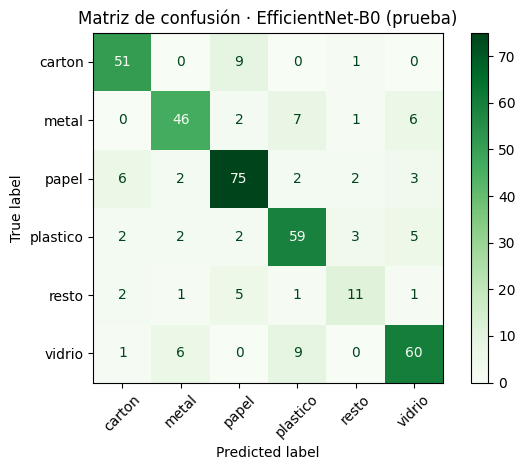

Accuracy balanceada: 75.5%


In [8]:
print(classification_report(reales, preds, target_names=CLASES, digits=3))   # precisión, recall y f1 por clase

ConfusionMatrixDisplay(confusion_matrix(reales, preds, labels=CLASES),
                       display_labels=CLASES).plot(cmap="Greens", xticks_rotation=45)
plt.title("Matriz de confusión · EfficientNet-B0 (prueba)"); plt.tight_layout(); plt.show()

print(f"Accuracy balanceada: {balanced_accuracy_score(reales, preds):.1%}")   # promedia el acierto de cada clase

**Pregunta 2 · el error más costoso.** En reciclaje, ¿qué confusión hace más daño?

> _Respuesta sugerida:_ Mandar un residuo **reciclable a "resto"** desperdicia material que se podía reciclar; pero mandar algo **que no es reciclable al contenedor de reciclaje contamina todo el lote** y puede arruinar lo demás. Miren en la matriz qué clase se confunde más y coméntenlo con sus números.

## 6. Comparación de los dos enfoques

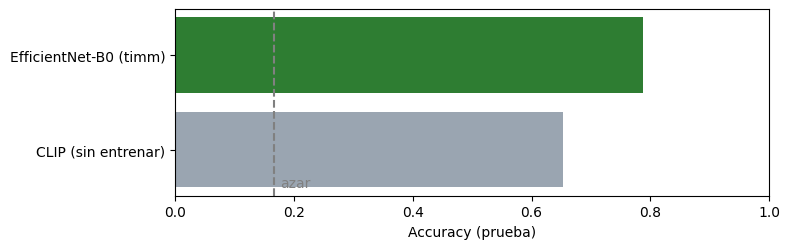

CLIP (sin entrenar)          65.3%
EfficientNet-B0 (timm)       78.9%


In [9]:
plt.figure(figsize=(8, 2.6))
plt.barh(list(RESULTADOS), list(RESULTADOS.values()), color=["#9aa5b1", "#2e7d32"])
plt.axvline(1 / len(CLASES), ls="--", color="gray")              # línea del azar (1/6)
plt.text(1 / len(CLASES) + 0.01, -0.4, "azar", color="gray")
plt.xlim(0, 1); plt.xlabel("Accuracy (prueba)"); plt.tight_layout(); plt.show()

for nombre, acc in RESULTADOS.items():
    print(f"{nombre:28s} {acc:.1%}")

**Pregunta 3.** ¿Cuánto mejoró entrenar EfficientNet frente a usar CLIP tal cual? ¿Por qué un modelo tan potente como CLIP rinde peor aquí?

> _Respuesta sugerida:_ EfficientNet suele ganar por harto, porque **se adaptó a nuestras clases y a este tipo de foto**. CLIP conoce "botella" o "lata" en general, pero no fue ajustado a estas 6 categorías. En resumen: un modelo general sabe de todo un poco; el transfer learning lo vuelve experto en nuestro problema.

## 7. Exportar el modelo para la app
Guardamos tres archivos en `modelo/`: los **pesos** entrenados (`modelo.pt`), las **clases** en el orden correcto (`clases.txt`) y un pequeño **config** con la arquitectura y la accuracy. La app los usará para reconstruir el modelo.

In [10]:
import json, shutil

os.makedirs("modelo", exist_ok=True)
torch.save(modelo.state_dict(), "modelo/modelo.pt")                          # pesos entrenados
with open("modelo/clases.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(CLASES))                                               # una clase por línea, en orden
with open("modelo/config.json", "w", encoding="utf-8") as f:
    json.dump({"arquitectura": "efficientnet_b0",
               "clases": CLASES,
               "accuracy_prueba": round(RESULTADOS["EfficientNet-B0 (timm)"], 4)},
              f, ensure_ascii=False, indent=2)

print(f"Modelo guardado: {os.path.getsize('modelo/modelo.pt')/1e6:.1f} MB (cabe en GitHub, < 100 MB)")

shutil.make_archive("modelo", "zip", "modelo")                               # lo empaquetamos
try:
    from google.colab import files
    files.download("modelo.zip")                                            # en Colab lo descarga a tu PC
except Exception:
    print("modelo.zip quedó en la carpeta del proyecto.")

Modelo guardado: 16.4 MB (cabe en GitHub, < 100 MB)


modelo.zip quedó en la carpeta del proyecto.


## 8. Checklist de este notebook
- [x] Dataset descrito: origen, licencia, clases, número de fotos y división train/val/test.
- [x] Revisión de calidad: imágenes verificadas, convertidas a RGB y desbalance comentado.
- [x] Comparación de **dos enfoques** con la **misma métrica** (CLIP vs EfficientNet).
- [x] Métricas en prueba: accuracy, matriz de confusión y reporte por clase.
- [x] Interpretación del error más costoso.
- [x] Modelo exportado (`modelo.pt` + `clases.txt` + `config.json`) para la app.

**Siguiente paso:** usar `modelo.pt` y `clases.txt` en `app.py` (Gradio), que conectará el resultado con el LLM.